# Neural Prophet

**NeuralProphet** is a forecasting library built on PyTorch that combines the interpretable decomposition of Facebook's **Prophet** with **neural network** components (AR-Net) to capture autoregressive patterns.

It models the series as a sum of components:

$$\hat{y}(t) = T(t) + S(t) + A(t) + E(t) + F(t) + L(t)$$

- $T(t)$: **trend**, piecewise linear with automatic changepoints
- $S(t)$: **seasonality**, modeled with Fourier terms (yearly, weekly, daily)
- $A(t)$: **auto-regression**, a neural net on the last $p$ lags (AR-Net)
- $E(t)$: **events** and holidays
- $F(t)$, $L(t)$: **future** and **lagged** external regressors

**Pros:** interpretable components, handles trend + seasonality automatically, can add lags and external variables easily.
**Cons:** needs more data than classical models, results vary between runs (neural training), and it's slower than ARIMA.

### Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter('ignore', ConvergenceWarning)

In [3]:
import time
import math
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from matplotlib import image as mpimg

In [4]:
def transform_date(date):
    try:
        new_date = date.year + (date.month - 1)/12 + date.day/365
        return new_date
    except:
        return float('nan')

In [5]:
def transform_value(value):
    try:
        return float(value)
    except:
        return float('nan')

In [6]:
start = time.time()

# 1. Read DataFrame

In [7]:
df = pd.read_csv('AirPassengers.csv')
df = df.rename(columns = {'Month': 'Time', 'Passengers': 'X_t'})
df['Time'] = pd.to_datetime(df['Time'])
df['Time'] = df['Time'].map(lambda x: transform_date(x))
df['X_t'] = df['X_t'].map(lambda x: transform_value(x))
df = df.dropna()

# 2. Split

In [8]:
train = df[df['Time'] <= 1955]
val = df[(df['Time'] > 1955) & (df['Time'] <= 1958)]
test = df[df['Time'] > 1958]

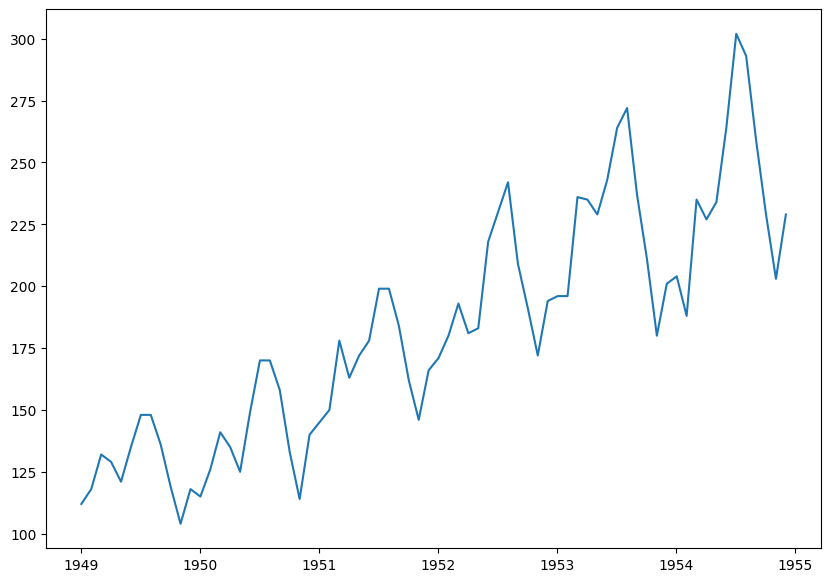

In [9]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['X_t'])
plt.show()

# 3. Box Cox

In [10]:
train['log_X_t'] = np.log(train['X_t'])
val['log_X_t'] = np.log(val['X_t'])
test['log_X_t'] = np.log(test['X_t'])

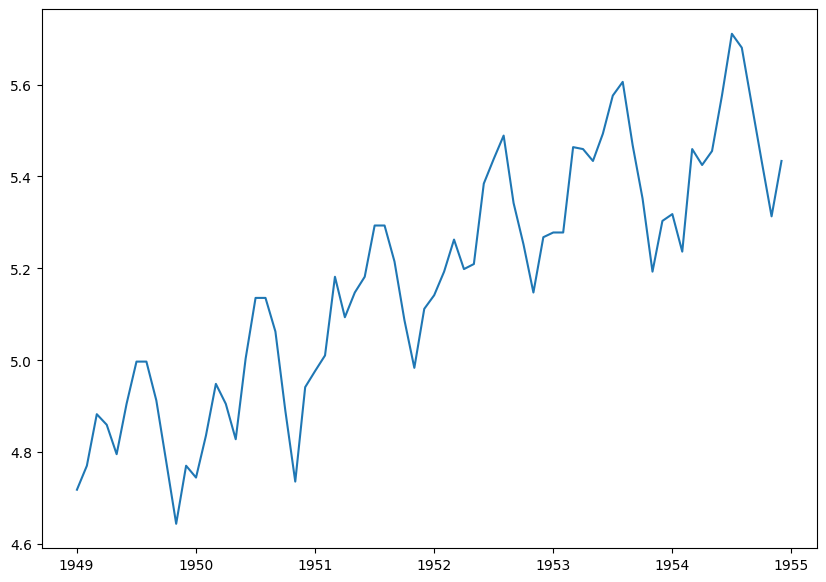

In [11]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_X_t'])
plt.show()

# 4. Exogen Regression

We dont have exogen variables.

# 5. Endogen Regression

We going to use linear trend.

In [12]:
from sklearn.linear_model import LinearRegression

In [13]:
reg = LinearRegression().fit(train[['Time']], train['log_X_t'])

In [14]:
train['log_trend'] = reg.predict(train[['Time']])
val['log_trend'] = reg.predict(val[['Time']])
test['log_trend'] = reg.predict(test[['Time']])

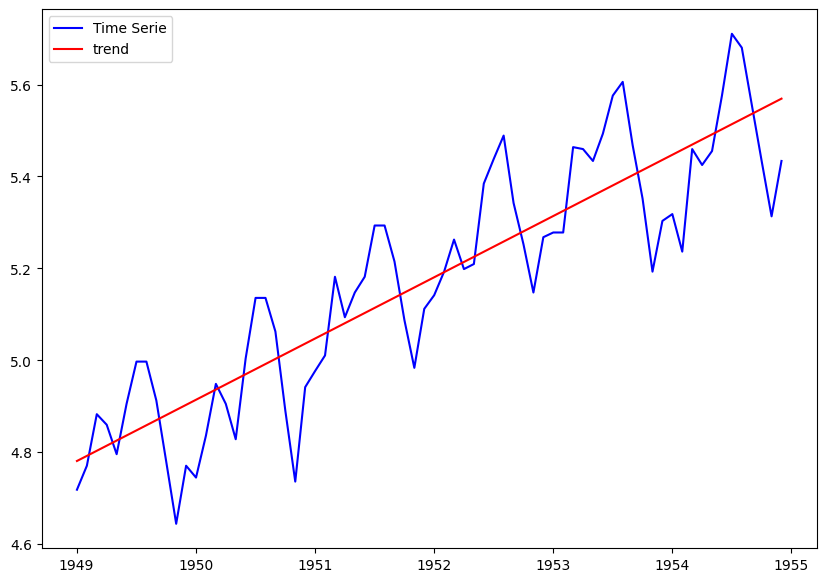

In [15]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_X_t'], color = 'blue', label = 'Time Serie')
plt.plot(train['Time'], train['log_trend'], color = 'red', label = 'trend')
plt.legend()
plt.show()

In [16]:
train['log_error'] = train['log_X_t'] - train['log_trend']
val['log_error'] = val['log_X_t'] - val['log_trend']
test['log_error'] = test['log_X_t'] - test['log_trend']

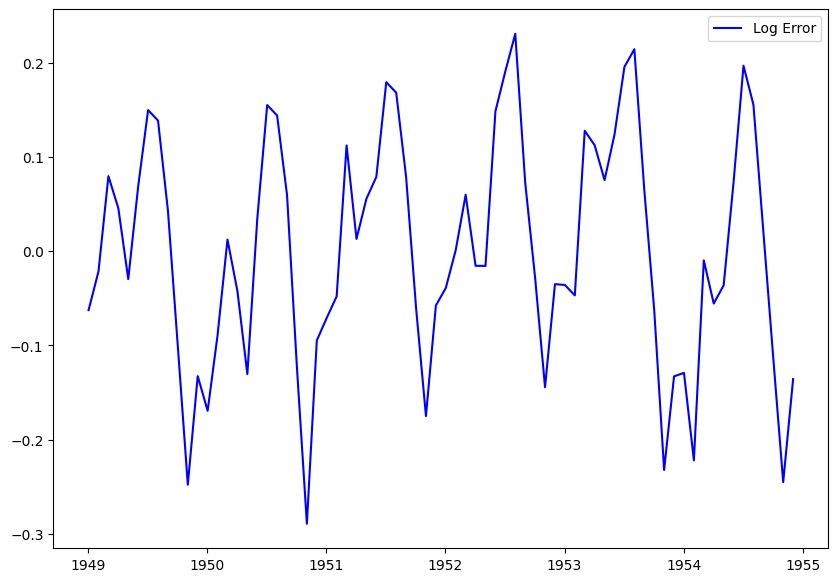

In [17]:
plt.figure(figsize = (10, 7))
plt.plot(train['Time'], train['log_error'], color = 'blue', label = 'Log Error')
plt.legend()
plt.show()

# Evaluation framework

Every model predicts only $\hat{Z}_2(t)$ (the log error). The forecast in the original scale is:

$$\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$$

We compare models on the validation set with RMSE and MAPE, always in the original scale (passengers).

# 6. Neural Prophet

In [18]:
from neuralprophet import NeuralProphet, set_log_level, set_random_seed

set_random_seed(0)

def to_ds(d):
    year = np.floor(d['Time']).astype(int)
    month = ((d['Time'] % 1) * 12).round().astype(int) + 1
    return pd.to_datetime(pd.DataFrame({'year': year, 'month': month, 'day': 1}))

In [19]:
df_np_train = pd.DataFrame({'ds': to_ds(train).values, 'y': train['log_error'].values})
df_np_val = pd.DataFrame({'ds': to_ds(val).values, 'y': val['log_error'].values})
df_np_test = pd.DataFrame({'ds': to_ds(test).values, 'y': test['log_error'].values})

In [20]:
model_np = NeuralProphet(
    growth='off',
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    epochs=300,
    learning_rate=0.01,
)
metrics_np = model_np.fit(df_np_train, freq='MS')

WARNING - (NP.forecaster.fit) - When Global modeling with local normalization, metrics are displayed in normalized scale.
INFO - (NP.df_utils._infer_frequency) - Major frequency MS corresponds to [98.611]% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - MS
INFO - (NP.config.init_data_params) - Setting normalization to global as only one dataframe provided for training.
INFO - (NP.config.set_auto_batch_epoch) - Auto-set batch_size to 8


Training: |          | 0/? [00:09<?, ?it/s, v_num=3, train_loss=0.0123, reg_loss=0.000, MAE=0.0378, RMSE=0.0453, Loss=0.0123, RegLoss=0.000]


# 7. Evaluate

In [21]:
forecast_train = model_np.predict(df_np_train)
forecast_val = model_np.predict(df_np_val)
forecast_test = model_np.predict(df_np_test)

z2_hat_train = forecast_train['yhat1'].values
z2_hat_val = forecast_val['yhat1'].values
z2_hat_test = forecast_test['yhat1'].values

train['X_hat_np'] = np.exp(z2_hat_train + train['log_trend'].values)
val['X_hat_np'] = np.exp(z2_hat_val + val['log_trend'].values)
test['X_hat_np'] = np.exp(z2_hat_test + test['log_trend'].values)

INFO - (NP.df_utils._infer_frequency) - Major frequency MS corresponds to [98.611]% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - MS
INFO - (NP.df_utils._infer_frequency) - Major frequency MS corresponds to [98.611]% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - MS


Predicting DataLoader 0: 100%|██████████| 1/1 [00:00<00:00, 257.21it/s]


INFO - (NP.df_utils.return_df_in_original_format) - Returning df with no ID column
INFO - (NP.df_utils._infer_frequency) - Major frequency MS corresponds to [97.222]% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - MS
INFO - (NP.df_utils._infer_frequency) - Major frequency MS corresponds to [97.222]% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - MS


Predicting DataLoader 0: 100%|██████████| 1/1 [00:00<00:00, 277.95it/s]


INFO - (NP.df_utils.return_df_in_original_format) - Returning df with no ID column
INFO - (NP.df_utils._infer_frequency) - Major frequency MS corresponds to [97.222]% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - MS
INFO - (NP.df_utils._infer_frequency) - Major frequency MS corresponds to [97.222]% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - MS


Predicting DataLoader 0: 100%|██████████| 1/1 [00:00<00:00, 613.47it/s] 

INFO - (NP.df_utils.return_df_in_original_format) - Returning df with no ID column


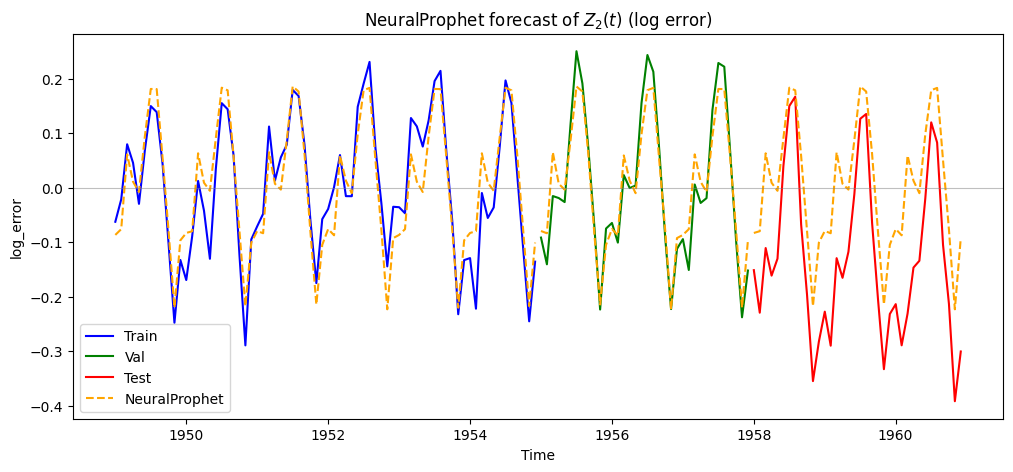

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(train['Time'], train['log_error'], color='blue', label='Train')
plt.plot(val['Time'], val['log_error'], color='green', label='Val')
plt.plot(test['Time'], test['log_error'], color='red', label='Test')
plt.plot(train['Time'], z2_hat_train, '--', color='orange', label='NeuralProphet')
plt.plot(val['Time'], z2_hat_val, '--', color='orange')
plt.plot(test['Time'], z2_hat_test, '--', color='orange')
plt.axhline(0, color='gray', linewidth=0.8, alpha=0.5)
plt.title(r'NeuralProphet forecast of $Z_2(t)$ (log error)')
plt.xlabel('Time'); plt.ylabel('log_error')
plt.legend(); plt.show()

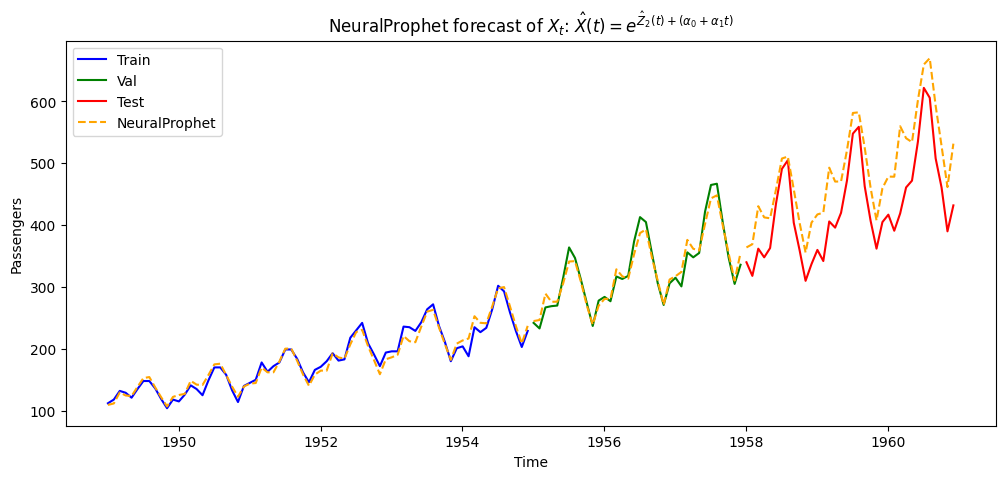

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(train['Time'], train['X_t'], color='blue', label='Train')
plt.plot(val['Time'], val['X_t'], color='green', label='Val')
plt.plot(test['Time'], test['X_t'], color='red', label='Test')
plt.plot(train['Time'], train['X_hat_np'], '--', color='orange', label='NeuralProphet')
plt.plot(val['Time'], val['X_hat_np'], '--', color='orange')
plt.plot(test['Time'], test['X_hat_np'], '--', color='orange')
plt.title(r'NeuralProphet forecast of $X_t$: $\hat{X}(t) = e^{\hat{Z}_2(t) + (\alpha_0 + \alpha_1 t)}$')
plt.xlabel('Time'); plt.ylabel('Passengers')
plt.legend(); plt.show()

In [24]:
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)

def performance(y_true, y_pred):
    return {
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(y_true, y_pred) * 100,
        'R2': r2_score(y_true, y_pred),
    }

rows = [
    {'Scale': 'log_error', 'Set': 'train', **performance(train['log_error'], z2_hat_train)},
    {'Scale': 'log_error', 'Set': 'val',   **performance(val['log_error'], z2_hat_val)},
    {'Scale': 'log_error', 'Set': 'test',  **performance(test['log_error'], z2_hat_test)},
    {'Scale': 'X_t',       'Set': 'train', **performance(train['X_t'], train['X_hat_np'])},
    {'Scale': 'X_t',       'Set': 'val',   **performance(val['X_t'], val['X_hat_np'])},
    {'Scale': 'X_t',       'Set': 'test',  **performance(test['X_t'], test['X_hat_np'])},
]

metrics_np_df = pd.DataFrame(rows).set_index(['Scale', 'Set']).round(4)
metrics_np_df

RMSE      MAE  MAPE (%)      R2
Scale     Set                                      
log_error train   0.0470   0.0378  172.5800  0.8543
          val     0.0370   0.0304  134.0454  0.9268
          test    0.1428   0.1314  118.6773  0.0870
X_t       train   8.7040   6.8658    3.7986  0.9662
          val    12.7897  10.2748    3.0446  0.9527
          test   63.6931  58.5318   14.2163  0.3369